## Lending Club Loan Data Analysis & Machine Learning Project
This project analyses the Lending Club dataset to demonstrate end_to_end data science skills: data loading, cleaning, exploratory data analysis (EDA), visualisation, feature engineering, machine learning, and bussiness insights.

Note: Due to the original dataset size (~1.6 GB), a reduce and cleaned version of the data (lending_club_cleaned.csv) was created by selecting only relevant columns. This ensures efficient processing while preserving analytical value.

-------

# Project Objective
- Analyse approved Lending Club loans
- Understand borrower and loan characteristics
- Identify factors associated with loan default
- Build a machine learning model to predict loan status

# Dataset Used:
- lending_club_cleaned.csv (derived from Kaggle Lending Club dataset)


## Importing Required Libraries

In [1]:
# Core libraries
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Display setting
pd.set_option("display.max_columns", None)

## Load the Dataset

In [2]:
# Load the dataset
df = pd.read_csv("lending_club_cleaned.csv", low_memory=False)

# Preview the data
df.head()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,loan_status,purpose,dti,open_acc,revol_bal,total_acc
0,3600.0,36 months,13.99,123.03,C,C4,10+ years,MORTGAGE,55000.0,Fully Paid,debt_consolidation,5.91,7.0,2765.0,13.0
1,24700.0,36 months,11.99,820.28,C,C1,10+ years,MORTGAGE,65000.0,Fully Paid,small_business,16.06,22.0,21470.0,38.0
2,20000.0,60 months,10.78,432.66,B,B4,10+ years,MORTGAGE,63000.0,Fully Paid,home_improvement,10.78,6.0,7869.0,18.0
3,35000.0,60 months,14.85,829.90,C,C5,10+ years,MORTGAGE,110000.0,Current,debt_consolidation,17.06,13.0,7802.0,17.0
4,10400.0,60 months,22.45,289.91,F,F1,3 years,MORTGAGE,104433.0,Fully Paid,major_purchase,25.37,12.0,21929.0,35.0


## Initial Data Exploration

In [3]:
# Dataset shape
df.shape

# Daraset structure
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Data columns (total 15 columns):
 #   Column          Dtype  
---  ------          -----  
 0   loan_amnt       float64
 1   term            str    
 2   int_rate        float64
 3   installment     float64
 4   grade           str    
 5   sub_grade       str    
 6   emp_length      str    
 7   home_ownership  str    
 8   annual_inc      float64
 9   loan_status     str    
 10  purpose         str    
 11  dti             float64
 12  open_acc        float64
 13  revol_bal       float64
 14  total_acc       float64
dtypes: float64(8), str(7)
memory usage: 258.7 MB


Note: The dataset is intentionally reduced to optimise memory usage and runtime while maintaining analytical relevance.

In [4]:
# Summary statistics
df.describe()

,loan_amnt,int_rate,installment,annual_inc,dti,open_acc,revol_bal,total_acc
count,2.260668e+06,2.260668e+06,2.260668e+06,2.260664e+06,2.258957e+06,2.260639e+06,2.260668e+06,2.260639e+06
mean,1.504693e+04,1.309283e+01,4.458068e+02,7.799243e+04,1.882420e+01,1.161240e+01,1.665846e+04,2.416255e+01
std,9.190245e+03,4.832138e+00,2.671735e+02,1.126962e+05,1.418333e+01,5.640861e+00,2.294831e+04,1.198753e+01
min,5.000000e+02,5.310000e+00,4.930000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
25%,8.000000e+03,9.490000e+00,2.516500e+02,4.600000e+04,1.189000e+01,8.000000e+00,5.950000e+03,1.500000e+01
50%,1.290000e+04,1.262000e+01,3.779900e+02,6.500000e+04,1.784000e+01,1.100000e+01,1.132400e+04,2.200000e+01
75%,2.000000e+04,1.599000e+01,5.933200e+02,9.300000e+04,2.449000e+01,1.400000e+01,2.024600e+04,3.100000e+01
max,4.000000e+04,3.099000e+01,1.719830e+03,1.100000e+08,9.990000e+02,1.010000e+02,2.904836e+06,1.760000e+02


# Data Cleaning

In [5]:
# Check missing values per column
df.isnull().sum()

loan_amnt             33
term                  33
int_rate              33
installment           33
grade                 33
sub_grade             33
emp_length        146940
home_ownership        33
annual_inc            37
loan_status           33
purpose               33
dti                 1744
open_acc              62
revol_bal             33
total_acc             62
dtype: int64

## Target Variable Creation

Loan Status Mapping:
- Fully Paid: 0 (Non-Default)
- Charged Off / Default: 1 (Default)

In [6]:
# Keep a copy before filtering
df = df.copy()

In [7]:
# Define defaulted loans more broadly
default_statuses = ["Charged Off", "Default", "Late (31-120 days)"]

# Filter relevant loan statuses
df["default"] = df["loan_status"].isin(default_statuses).astype(int)

# Verify target encoding
df["loan_status"].value_counts()

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

## Exploratory Data Analysis (EDA)

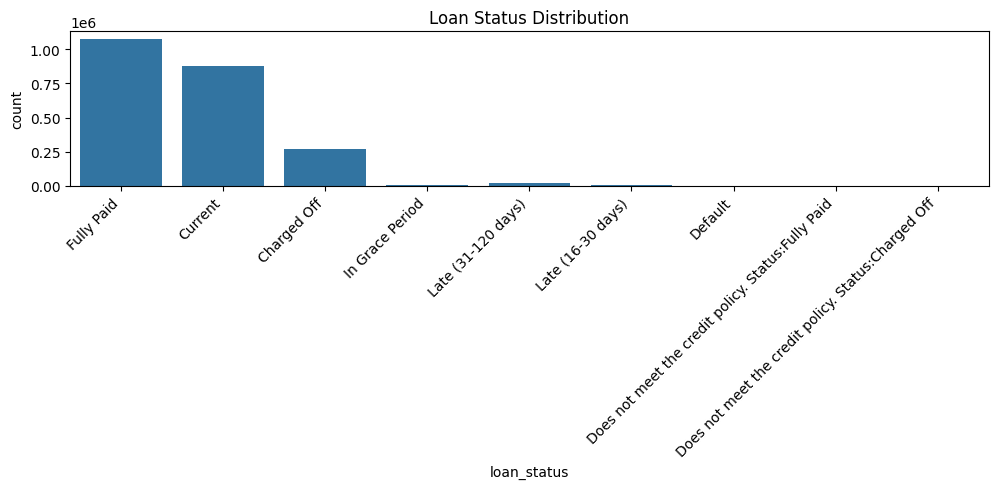

In [8]:
# Loan outcome distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="loan_status")
plt.xticks(rotation=45, ha="right")
plt.title("Loan Status Distribution")
plt.tight_layout()
plt.show()

## Insight:
The dataset is imbalanced, with significatly more fully paid loans than defaults.

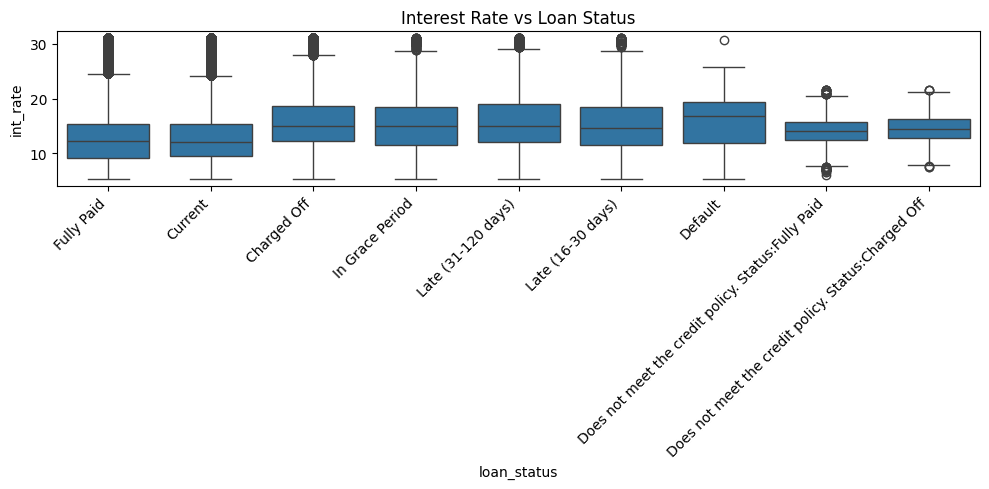

In [9]:
# Interest rate vs loan status
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="loan_status", y="int_rate")
plt.title("Interest Rate vs Loan Status")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Insights:
Default loans generally have higher interest rates, reflecting higher borrower risk.

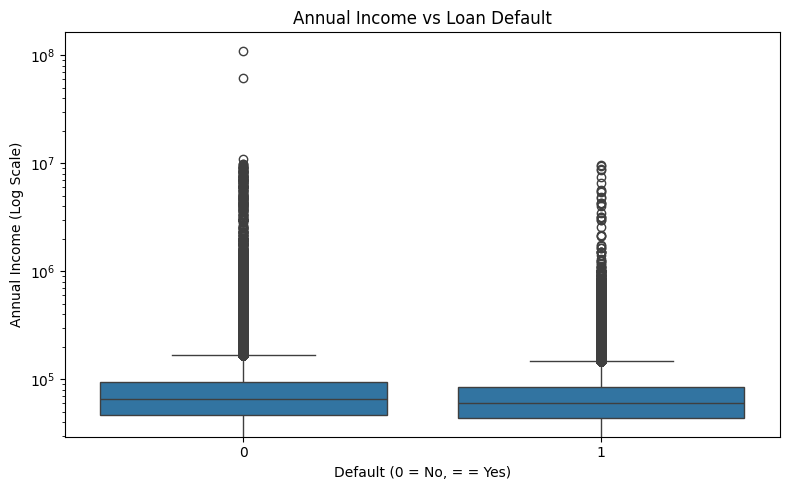

In [10]:
# Annual income vs default
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="default", y="annual_inc")
plt.yscale("log")
plt.title("Annual Income vs Loan Default")
plt.xlabel("Default (0 = No, = = Yes)")
plt.ylabel("Annual Income (Log Scale)")
plt.tight_layout()
plt.show()

## Insights:
Lower income borrowers show a higher likelihood of default.

# Machine Learning Approach

## Machine Learning Model
We use "Logistic Regression"
- Simple
- Interpretable
- Appropriate for binary classification
 
Class imbalance was addressed using stratified sampling and balanced class weights.


In [11]:
# Feature selection
features = [
    "loan_amnt",
    "int_rate",
    "installment",
    "annual_inc",
    "dti",
    "open_acc",
    "revol_bal",
    "total_acc"
]

# Drop rows olny ML features are missing
df = df.dropna(subset=features + ["default"])

# Define X and y
X = df[features]
y = df["default"]

# Safety check 
assert y.nunique() == 2 #(Target variable must have 2 classes)

# Train, Test, Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model Training
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_scaled, y_train)

# Model Evaluation
# Prediction
y_pred = model.predict(X_test_scaled)

# Classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.66      0.77    393792
           1       0.21      0.59      0.31     57994

    accuracy                           0.65    451786
   macro avg       0.56      0.63      0.54    451786
weighted avg       0.83      0.65      0.71    451786



## Limitations and Future Improvments

- The dataset is imbalanced, which limits recall for default loans
- Only a subset of available Lending Club features was used
- More advanced models (Random Forest, XGBoost) could improve performance
- Feature engineering (e.g. credit history lenght) may enhance predictions